# Image-to-Image Change Detection

*Section 6 — Change detection, notebook 3 of 5.* Previous: `02_map_to_map_change`. Next: `04_map_to_image_change`.

**You will learn:**
- how to calculate spectral indices (NDVI, WBI) with `calc_indices`;
- how to detect change from the difference and the ratio of two NDVI images;
- how to use those changes to update the baseline classification and create a from–to change map, named and coloured with `set_thematic_classes`.

**Before you start:** run `01_create_baseline_class` and `02_map_to_map_change` first; this notebook reads the 1997 classification and the 1997 and 2018 valid-data masks from `outputs/baseline_cls` and `outputs/2018_cls`.

**Data:** `../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 5 TM, 1997) and `../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 8, 2018).

**Run time:** about 1 minute.

## What is Image-to-Image Change?

Image-to-Image change detection processes compare the pixel values of two (or more) EO image datasets and if those values are different then a change occurs. These algorithms are **sensitive to seasonal, geometry and modality changes** which can result in false positives. However, these methods are useful as they are **quick to implement** and **don't require background knowledge** on the land covers or make you decide on a particular key. The simplest approach for such methods is to take a simple difference between two image bands or derived indices (e.g., NDVI).

## What are the steps:

This is quite a simple method, basically just take the difference between the images. In this notebook we will go through the process of using a difference and a ratio to perform an image-to-image change detection.

rsgispy also has ready-made image-to-image methods in `rsgispy.changedetect.imgchngmthds` (`image_difference`, `image_ratio`, `change_vector_analysis`, ...); see the rsgispy change detection guide. Here we use `band_maths` so you can see each step.

## 1. Define Imports

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt

import rsgispy
from rsgispy.imagecalc.calcindices import calc_indices
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.stats import pop_img_stats
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.mapping.raster import create_raster_cmap_img_map, create_thematic_raster_map

# The classes of the classifications (as in notebooks 01 and 02):
# pixel value: (class name, (red, green, blue))
cls_info = {
    1: ("mangroves", (0, 255, 0)),
    2: ("other_terrestrial", (180, 180, 180)),
    3: ("water", (0, 0, 255)),
}

# The from-to change classes (1997 class followed by the 2018 class).
chng_cls_info = {
    11: ("Mangrove_Mangrove", (25, 200, 25)),
    12: ("Mangrove_Terrestrial", (200, 100, 25)),
    13: ("Mangrove_Water", (200, 25, 200)),
    21: ("Terrestrial_Mangrove", (125, 100, 125)),
    22: ("Terrestrial_Terrestrial", (125, 125, 125)),
    23: ("Terrestrial_Water", (125, 125, 100)),
    31: ("Water_Mangrove", (25, 255, 200)),
    32: ("Water_Terrestrial", (62, 62, 200)),
    33: ("Water_Water", (25, 25, 200)),
}

## 2. Define Input Images

In [2]:
# The outputs of notebooks 01 and 02.
cls_1997_dir = os.path.join("outputs", "baseline_cls")
cls_2018_dir = os.path.join("outputs", "2018_cls")

img_to_img_chg_dir = os.path.join("outputs", "img_to_img_chg")
os.makedirs(img_to_img_chg_dir, exist_ok=True)

# File path to the 1997 classification
cls_1997_img = os.path.join(cls_1997_dir, "base_1997_class_img.tif")

# File path to the input Landsat 5 image from 1997.
input_97_img = (
    "../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# File path to the Landsat 5 valid data mask from 1997
vld_97_img = os.path.join(cls_1997_dir, "LS5TM_19970716_vmsk.tif")

# File path to the input Landsat 8 image from 2018.
input_18_img = (
    "../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# File path to the Landsat 8 valid data mask from 2018.
vld_18_img = os.path.join(cls_2018_dir, "LS8_20180608_vmsk.tif")

## 3. Calculate NDVI and WBI

For this notebook we will use the NDVI index to define the change between the two images, and the water band index (WBI = blue / NIR) to help identify water.

`calc_indices` takes a `band_names` dictionary mapping band numbers to band names (`red`, `nir`, `blue`, ...) and a list of the indices to calculate; `get_available_indices()` lists the names. Note the band numbers differ between the two sensors: Landsat 5 TM has red = 3 and NIR = 4, while Landsat 8 has blue = 2, red = 4 and NIR = 5.

**RSGISLib users:** `calc_ndvi` and `calc_wbi` are replaced by the single `calc_indices` function.

In [3]:
ls_1997_ndvi_img = os.path.join(img_to_img_chg_dir, "LS5TM_19970716_ndvi.tif")
calc_indices(
    input_97_img,
    ls_1997_ndvi_img,
    band_names={3: "red", 4: "nir"},
    indices=["NDVI"],
    no_data_val=0,
    out_no_data_val=-999.0,
    use_pbar=False,
)

ls_2018_ndvi_img = os.path.join(img_to_img_chg_dir, "LS8_20180608_ndvi.tif")
calc_indices(
    input_18_img,
    ls_2018_ndvi_img,
    band_names={4: "red", 5: "nir"},
    indices=["NDVI"],
    no_data_val=0,
    out_no_data_val=-999.0,
    use_pbar=False,
)

ls_2018_wbi_img = os.path.join(img_to_img_chg_dir, "LS8_20180608_wbi.tif")
calc_indices(
    input_18_img,
    ls_2018_wbi_img,
    band_names={2: "blue", 5: "nir"},
    indices=["WBI"],
    no_data_val=0,
    out_no_data_val=-999.0,
    use_pbar=False,
)

## 4. Image to Image Difference Change

### 4.1 Calculate NDVI Difference

Note, this needs to be for regions which are valid in both images.

In [4]:
ndvi_diff_img = os.path.join(img_to_img_chg_dir, "ndvi_diff_1997_2018.tif")

band_defns = [
    BandDefn("vld_97_msk", vld_97_img, 1),
    BandDefn("vld_18_msk", vld_18_img, 1),
    BandDefn("ndvi_97", ls_1997_ndvi_img, 1),
    BandDefn("ndvi_18", ls_2018_ndvi_img, 1),
]

exp = "(vld_18_msk==1)&&(vld_97_msk==1)?ndvi_97-ndvi_18:0"

band_maths(ndvi_diff_img, exp, band_defns, datatype=rsgispy.TYPE_32FLOAT, use_pbar=False)

pop_img_stats(ndvi_diff_img, no_data_val=0, calc_pyramids=True, use_pbar=False)

### 4.2 Visualise NDVI Difference Image

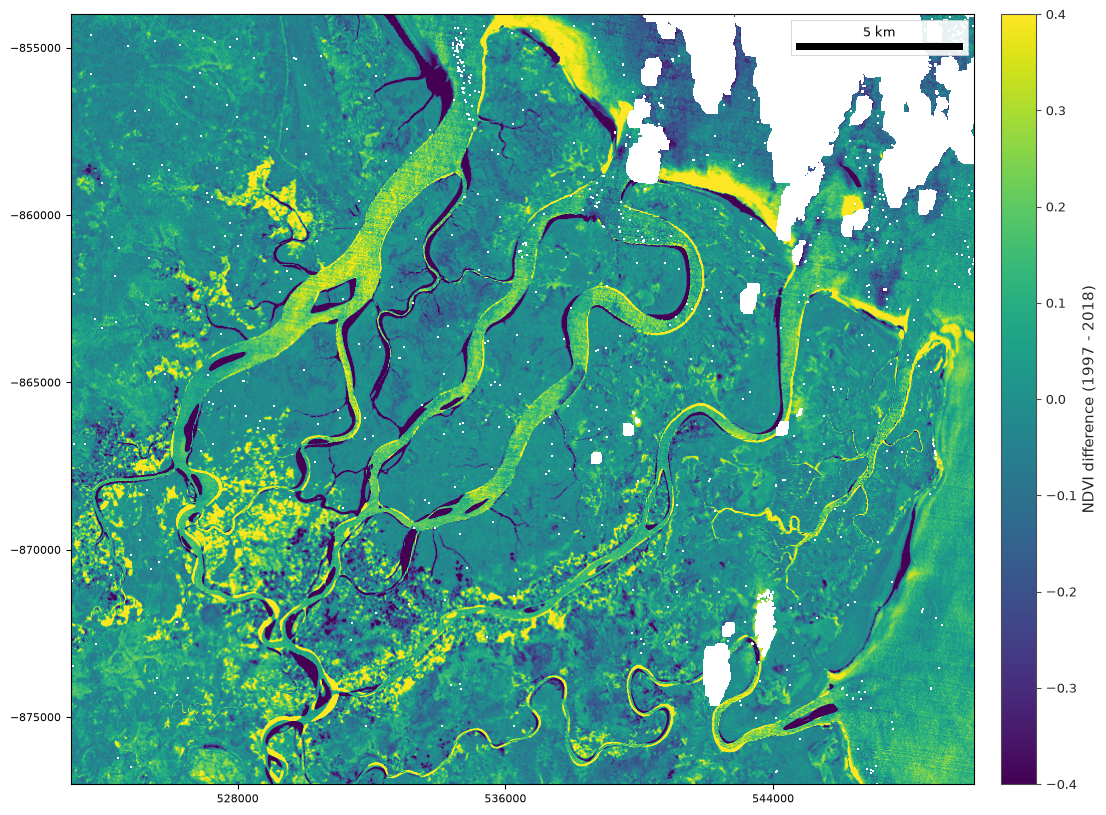

In [5]:
sub_bbox = [523000, 550000, -877000, -854000]

# Create the matplotlib figure
fig, ax = plt.subplots(figsize=(13, 10))

# Plot the NDVI difference.
img = create_raster_cmap_img_map(
    ax,
    ndvi_diff_img,
    img_band=1,
    bbox=sub_bbox,
    cmap_name="viridis",
    norm_img_vals=True,
    norm_vmin=-0.4,
    norm_vmax=0.4,
    show_scale_bar=True,
    show_colour_bar=True,
    cbar_label="NDVI difference (1997 - 2018)",
)

### 4.3 Update 1997 Classification to 2018

The 1997 classification is updated using the NDVI difference (1997 – 2018): mangroves with a large NDVI decrease (difference > 0.35) become other terrestrial, and water with a large NDVI increase (difference < -0.35) becomes mangrove.

In [6]:
chng_diff_2018_cls_img = os.path.join(img_to_img_chg_dir, "chng_map_diff_2018_img2img.tif")

band_defns = [
    BandDefn("vld_18_msk", vld_18_img, 1),
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("ndvi_diff", ndvi_diff_img, 1),
]
exp = """(vld_18_msk==1)&&(cls_1997==1)&&(ndvi_diff<0.35)&&(ndvi_diff>-0.35)?1:
         (vld_18_msk==1)&&(cls_1997==1)&&(ndvi_diff>0.35)?2:
         (vld_18_msk==1)&&(cls_1997==1)?1:
         (vld_18_msk==1)&&(cls_1997==2)?2:
         (vld_18_msk==1)&&(cls_1997==3)&&(ndvi_diff<-0.35)?1:
         (vld_18_msk==1)&&(cls_1997==3)?3:0
      """
band_maths(chng_diff_2018_cls_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)
set_thematic_classes(chng_diff_2018_cls_img, cls_info)

### 4.4 Create Change Image

As in notebook 02, each pixel is given a two digit code: the 1997 class followed by the 2018 class.

In [7]:
# Define output image path
chng_map_diff_img = os.path.join(img_to_img_chg_dir, "chng_map_1997_2018_diff_img2img.tif")

# Define the input image bands
band_defns = [
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("cls_2018", chng_diff_2018_cls_img, 1),
]

# Expression to define change classes
exp = """(cls_1997==1)&&(cls_2018==1)?11:
         (cls_1997==1)&&(cls_2018==2)?12:
         (cls_1997==1)&&(cls_2018==3)?13:
         (cls_1997==2)&&(cls_2018==1)?21:
         (cls_1997==2)&&(cls_2018==2)?22:
         (cls_1997==2)&&(cls_2018==3)?23:
         (cls_1997==3)&&(cls_2018==1)?31:
         (cls_1997==3)&&(cls_2018==2)?32:
         (cls_1997==3)&&(cls_2018==3)?33:0
      """

# Run band_maths
band_maths(chng_map_diff_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)


### 4.5 Colour and Name Change Classes

`set_thematic_classes` writes the colours to the image colour table and stores the class names in the image (the `chng_cls_info` dictionary defined with the imports), and calculates the statistics and pyramids. The map legend reads the names from the image.

**RSGISLib users:** this replaces `rastergis.set_class_names_colours` (rsgispy does not use raster attribute tables; the names are stored as a GeoTIFF band tag).

In [8]:
set_thematic_classes(chng_map_diff_img, chng_cls_info)

### 4.6 Visualise the NDVI Difference Change Map

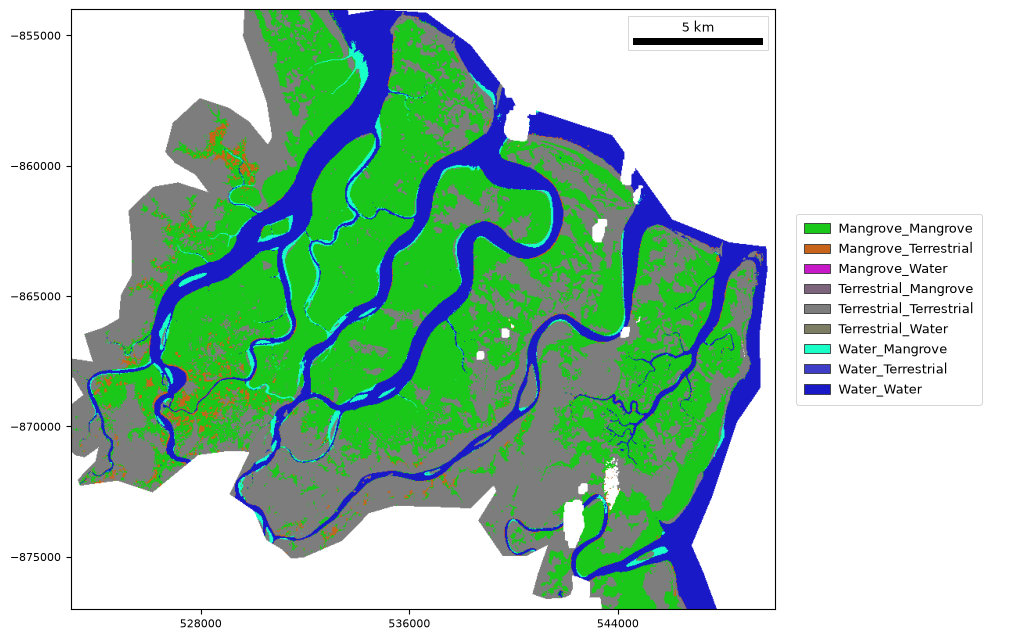

In [9]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, ax = plt.subplots(figsize=(12, 10))

# Plot Difference Map
img = create_thematic_raster_map(
    ax,
    chng_map_diff_img,
    bbox=sub_bbox,
    show_legend=True,
    legend_ncols=1,
)

## 5. Image to Image Ratio Change

### 5.1 Calculate NDVI Ratio

Where the 2018 NDVI is 0 the ratio is undefined, so those pixels are also set to 0 (no data).

In [10]:
ndvi_ratio_img = os.path.join(img_to_img_chg_dir, "ndvi_ratio_1997_2018.tif")

band_defns = [
    BandDefn("vld_97_msk", vld_97_img, 1),
    BandDefn("vld_18_msk", vld_18_img, 1),
    BandDefn("ndvi_97", ls_1997_ndvi_img, 1),
    BandDefn("ndvi_18", ls_2018_ndvi_img, 1),
]

exp = "(vld_18_msk==1)&&(vld_97_msk==1)&&(ndvi_18!=0)?ndvi_97/ndvi_18:0"

band_maths(ndvi_ratio_img, exp, band_defns, datatype=rsgispy.TYPE_32FLOAT, use_pbar=False)

pop_img_stats(ndvi_ratio_img, no_data_val=0, calc_pyramids=True, use_pbar=False)

### 5.2 Visualise NDVI Ratio

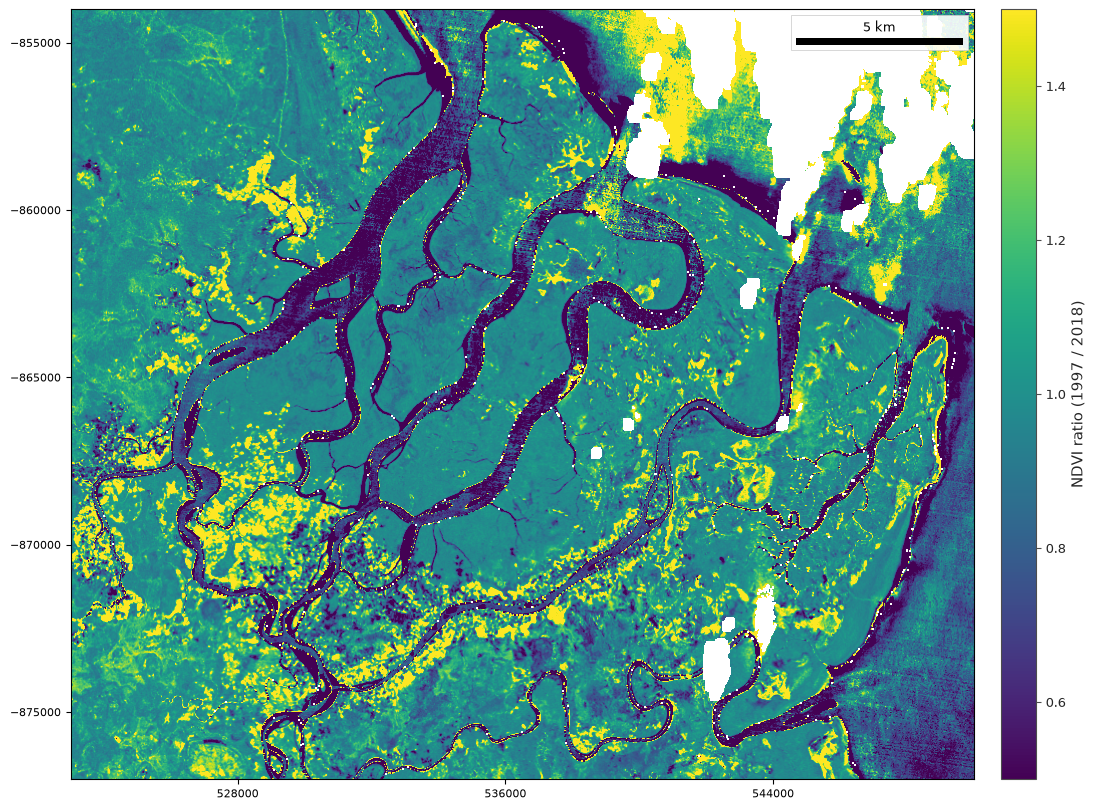

In [11]:
sub_bbox = [523000, 550000, -877000, -854000]

# Create the matplotlib figure
fig, ax = plt.subplots(figsize=(13, 10))

img = create_raster_cmap_img_map(
    ax,
    ndvi_ratio_img,
    img_band=1,
    bbox=sub_bbox,
    cmap_name="viridis",
    norm_img_vals=True,
    norm_vmin=0.5,
    norm_vmax=1.5,
    show_scale_bar=True,
    show_colour_bar=True,
    cbar_label="NDVI ratio (1997 / 2018)",
)

### 5.3 Update 1997 Classification to 2018

Mangroves with a large NDVI decrease (ratio > 1.3) become other terrestrial, and water pixels with a large NDVI increase (ratio < 0.1) and a low WBI (i.e., not water) become mangrove.

In [12]:
chng_ratio_2018_cls_img = os.path.join(img_to_img_chg_dir, "chng_map_ratio_2018_img2img.tif")

band_defns = [
    BandDefn("vld_18_msk", vld_18_img, 1),
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("ndvi_ratio", ndvi_ratio_img, 1),
    BandDefn("wbi_18", ls_2018_wbi_img, 1),
]
exp = """(vld_18_msk==1)&&(cls_1997==1)&&(ndvi_ratio<1.3)&&(ndvi_ratio>0.7)?1:
         (vld_18_msk==1)&&(cls_1997==1)&&(ndvi_ratio>1.3)?2:
         (vld_18_msk==1)&&(cls_1997==1)?1:
         (vld_18_msk==1)&&(cls_1997==2)?2:
         (vld_18_msk==1)&&(cls_1997==3)&&(ndvi_ratio<0.1)&&(wbi_18<0.4)?1:
         (vld_18_msk==1)&&(cls_1997==3)?3:0
      """
band_maths(chng_ratio_2018_cls_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)
set_thematic_classes(chng_ratio_2018_cls_img, cls_info)

### 5.4 Create Change Image

In [13]:
# Define output image path
chng_map_ratio_img = os.path.join(img_to_img_chg_dir, "chng_map_1997_2018_ratio_img2img.tif")

# Define the input image bands
band_defns = [
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("cls_2018", chng_ratio_2018_cls_img, 1),
]

# Expression to define change classes
exp = """(cls_1997==1)&&(cls_2018==1)?11:
         (cls_1997==1)&&(cls_2018==2)?12:
         (cls_1997==1)&&(cls_2018==3)?13:
         (cls_1997==2)&&(cls_2018==1)?21:
         (cls_1997==2)&&(cls_2018==2)?22:
         (cls_1997==2)&&(cls_2018==3)?23:
         (cls_1997==3)&&(cls_2018==1)?31:
         (cls_1997==3)&&(cls_2018==2)?32:
         (cls_1997==3)&&(cls_2018==3)?33:0
      """

# Run band_maths
band_maths(chng_map_ratio_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)


### 5.5 Colour and Name the Change Classes

We use the same class names and colours (`chng_cls_info`) as for the difference change map.

In [14]:
set_thematic_classes(chng_map_ratio_img, chng_cls_info)

### 5.6 Visualise the NDVI Ratio Change Map

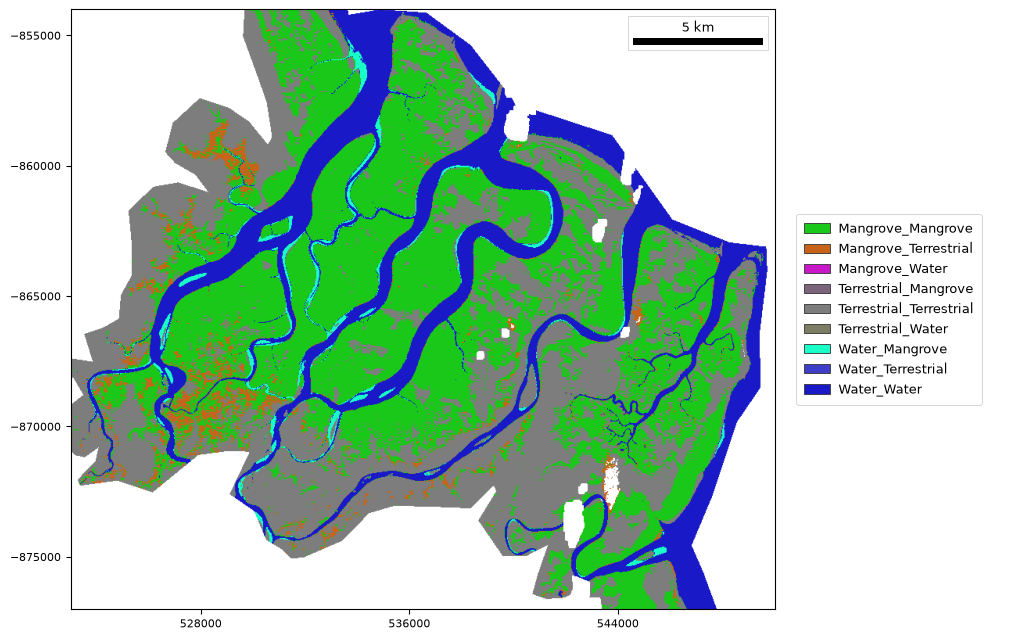

In [15]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, ax = plt.subplots(figsize=(12, 10))

# Plot change map
img = create_thematic_raster_map(
    ax,
    chng_map_ratio_img,
    bbox=sub_bbox,
    show_legend=True,
    legend_ncols=1,
)

## 6. Compare Image-to-Image Results

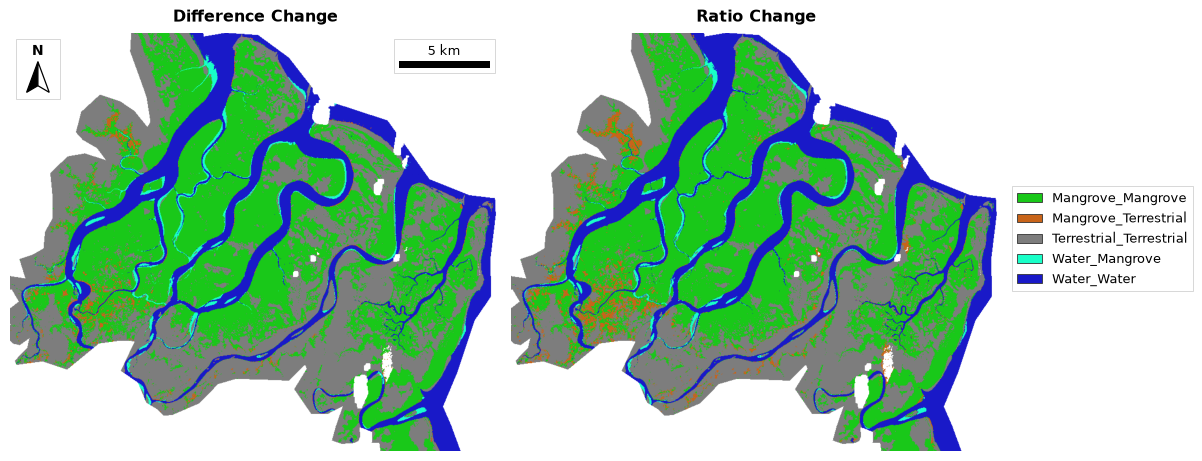

In [16]:
sub_bbox = [523000, 550000, -877000, -854000]

# The two change maps side by side, with one legend of the change classes
# present in either of them.
fig, axs = create_map_panels(
    [
        MapPanel("thematic", chng_map_diff_img, title="Difference Change"),
        MapPanel("thematic", chng_map_ratio_img, title="Ratio Change"),
    ],
    bbox=sub_bbox,
)

## Observations of the results

What you can probably see looking at the two change classifications is that the ratio based change has been more sensitive to the loss of mangrove than the difference based change. However, for the gain of mangroves from water it would appear the sensitivity is pretty similar.